In [1]:

import GEOparse

# 下载 GSE42568
gse = GEOparse.get_GEO(
    geo="GSE42568",
    destdir="data"
)

print("样本总数：", len(gse.gsms))
print("平台数量：", len(gse.gpls))

# 查看前几个样本的信息
for i, (gsm_id, sample) in enumerate(gse.gsms.items()):
    if i >= 3:
        break

    print("\n样本编号：", gsm_id)
    print("样本标题：", sample.metadata.get("title"))
    print("样本特征：", sample.metadata.get("characteristics_ch1"))


27-Oct-2026 18:31:30 DEBUG utils - Directory data already exists. Skipping.
27-Oct-2026 18:31:30 INFO GEOparse - File already exist: using local version.
27-Oct-2026 18:31:30 INFO GEOparse - Parsing data\GSE42568_family.soft.gz: 
27-Oct-2026 18:31:30 DEBUG GEOparse - DATABASE: GeoMiame
27-Oct-2026 18:31:30 DEBUG GEOparse - SERIES: GSE42568
27-Oct-2026 18:31:30 DEBUG GEOparse - PLATFORM: GPL570
d:\Anaconda\envs\cuda\Lib\site-packages\GEOparse\GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")
27-Oct-2026 18:31:31 DEBUG GEOparse - SAMPLE: GSM1045191
27-Oct-2026 18:31:31 DEBUG GEOparse - SAMPLE: GSM1045192
27-Oct-2026 18:31:31 DEBUG GEOparse - SAMPLE: GSM1045193
27-Oct-2026 18:31:31 DEBUG GEOparse - SAMPLE: GSM1045194
27-Oct-2026 18:31:31 DEBUG GEOparse - SAMPLE: GSM1045195
27-Oct-2026 18:31:31 DEBUG GEOparse - SAMPLE: GSM1045196
27-Oct-2026 18:31:31 DEBUG GEOparse

样本总数： 121
平台数量： 1

样本编号： GSM1045191
样本标题： ['Normal breast, N1_15_12_04']
样本特征： ['tissue: normal breast', 'age: NA', 'er_status: NA', 'size: NA', 'grade: NA', 'lymph node status: NA', 'relapse free survival time_days: NA', 'relapse free survival event: NA', 'overall survival time_days: NA', 'overall survival event: NA']

样本编号： GSM1045192
样本标题： ['Normal breast, N4_14_12_04']
样本特征： ['tissue: normal breast', 'age: NA', 'er_status: NA', 'size: NA', 'grade: NA', 'lymph node status: NA', 'relapse free survival time_days: NA', 'relapse free survival event: NA', 'overall survival time_days: NA', 'overall survival event: NA']

样本编号： GSM1045193
样本标题： ['Normal breast, N5_15_12_04']
样本特征： ['tissue: normal breast', 'age: NA', 'er_status: NA', 'size: NA', 'grade: NA', 'lymph node status: NA', 'relapse free survival time_days: NA', 'relapse free survival event: NA', 'overall survival time_days: NA', 'overall survival event: NA']


In [2]:

import pandas as pd

rows = []

for gsm_id, sample in gse.gsms.items():
    rows.append({
        "sample_id": gsm_id,
        "title": sample.metadata.get("title", [""])[0],
        "source": sample.metadata.get("source_name_ch1", [""])[0],
        "characteristics": "; ".join(
            sample.metadata.get("characteristics_ch1", [])
        )
    })

meta = pd.DataFrame(rows)

print(meta.head(10).to_string(index=False))

# 保存样本信息，方便检查
meta.to_csv("data/sample_metadata.csv", index=False)

print("\n样本信息已保存到 data/sample_metadata.csv")


 sample_id                      title                source                                                                                                                                                                                                             characteristics
GSM1045191 Normal breast, N1_15_12_04 Breast tissue, normal tissue: normal breast; age: NA; er_status: NA; size: NA; grade: NA; lymph node status: NA; relapse free survival time_days: NA; relapse free survival event: NA; overall survival time_days: NA; overall survival event: NA
GSM1045192 Normal breast, N4_14_12_04 Breast tissue, normal tissue: normal breast; age: NA; er_status: NA; size: NA; grade: NA; lymph node status: NA; relapse free survival time_days: NA; relapse free survival event: NA; overall survival time_days: NA; overall survival event: NA
GSM1045193 Normal breast, N5_15_12_04 Breast tissue, normal tissue: normal breast; age: NA; er_status: NA; size: NA; grade: NA; lymph node status: NA; relapse f

In [3]:

# 1. 统计组织类型
print("=== 组织类型统计 ===")
print(meta["source"].value_counts(dropna=False))

# 2. 统计样本标题的类型
print("\n=== 样本标题类型统计 ===")
print(
    meta["title"]
    .str.split(",")
    .str[0]
    .value_counts(dropna=False)
)


=== 组织类型统计 ===
source
Breast tissue, cancer    104
Breast tissue, normal     17
Name: count, dtype: int64

=== 样本标题类型统计 ===
title
Breast cancer    104
Normal breast     17
Name: count, dtype: int64


In [4]:

# 统计 ER 状态
print("\n=== ER 状态统计 ===")

er_values = []

for gsm_id, sample in gse.gsms.items():
    characteristics = sample.metadata.get(
        "characteristics_ch1", []
    )

    er_status = "未找到"

    for item in characteristics:
        if item.lower().startswith("er_status:"):
            er_status = item.split(":", 1)[1].strip()
            break

    er_values.append({
        "sample_id": gsm_id,
        "er_status": er_status
    })

er_df = pd.DataFrame(er_values)

print(er_df["er_status"].value_counts(dropna=False))



=== ER 状态统计 ===
er_status
1     67
0     34
NA    20
Name: count, dtype: int64


In [5]:

import pandas as pd

groups = []

for gsm_id, sample in gse.gsms.items():
    characteristics = sample.metadata.get(
        "characteristics_ch1", []
    )

    er_status = None
    tissue = None

    for item in characteristics:
        key, sep, value = item.partition(":")
        if not sep:
            continue

        key = key.strip().lower()
        value = value.strip()

        if key == "er_status":
            er_status = value
        elif key == "tissue":
            tissue = value.lower()

    if tissue == "normal breast":
        group = "Normal"
    elif tissue in ("breast cancer", "cancer") and er_status == "1":
        group = "ER_positive_tumor"
    else:
        group = "Exclude"

    groups.append({
        "sample_id": gsm_id,
        "tissue": tissue,
        "er_status": er_status,
        "group": group
    })

group_df = pd.DataFrame(groups)

print(group_df["group"].value_counts())

print("\n分组示例：")
print(group_df.head(10).to_string(index=False))

group_df.to_csv("data/sample_groups.csv", index=False)


group
ER_positive_tumor    67
Exclude              37
Normal               17
Name: count, dtype: int64

分组示例：
 sample_id        tissue er_status  group
GSM1045191 normal breast        NA Normal
GSM1045192 normal breast        NA Normal
GSM1045193 normal breast        NA Normal
GSM1045194 normal breast        NA Normal
GSM1045195 normal breast        NA Normal
GSM1045196 normal breast        NA Normal
GSM1045197 normal breast        NA Normal
GSM1045198 normal breast        NA Normal
GSM1045199 normal breast        NA Normal
GSM1045200 normal breast        NA Normal


In [6]:

# 查看平台信息
for gpl_id, platform in gse.gpls.items():
    print("平台编号：", gpl_id)
    print("平台名称：", platform.metadata.get("title", ["未知"])[0])
    print("平台表格形状：", platform.table.shape)
    print("\n平台表格列名：")
    print(platform.table.columns.tolist()[:20])

# 查看一个样本的数据表
sample_id = next(iter(gse.gsms))
sample = gse.gsms[sample_id]

print("\n样本编号：", sample_id)
print("样本数据表形状：", sample.table.shape)
print("样本数据表列名：")
print(sample.table.columns.tolist())
print("\n样本数据表前5行：")
print(sample.table.head())


平台编号： GPL570
平台名称： [HG-U133_Plus_2] Affymetrix Human Genome U133 Plus 2.0 Array
平台表格形状： (54675, 16)

平台表格列名：
['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']

样本编号： GSM1045191
样本数据表形状： (54675, 2)
样本数据表列名：
['ID_REF', 'VALUE']

样本数据表前5行：
      ID_REF     VALUE
0  1007_s_at  5.640239
1    1053_at  5.074866
2     117_at  4.191770
3     121_at  3.574706
4  1255_g_at  2.312812


In [7]:

import pandas as pd

# 逐个样本提取表达值
expression_data = {}

for gsm_id, sample in gse.gsms.items():
    sample_table = sample.table[["ID_REF", "VALUE"]].copy()

    # 将探针 ID 设为索引
    sample_table = sample_table.set_index("ID_REF")

    # 将表达值存入对应样本列
    expression_data[gsm_id] = sample_table["VALUE"]

# 合并成表达矩阵
expr = pd.DataFrame(expression_data)

print("表达矩阵形状：", expr.shape)
print("\n前5行、前5个样本：")
print(expr.iloc[:5, :5])

print("\n是否存在缺失值：", expr.isna().sum().sum())
print("探针 ID 是否有重复：", expr.index.duplicated().sum())

# 保存表达矩阵
expr.to_csv("data/GSE42568_expression_matrix.csv")
print("\n表达矩阵已保存。")


表达矩阵形状： (54675, 121)

前5行、前5个样本：
           GSM1045191  GSM1045192  GSM1045193  GSM1045194  GSM1045195
ID_REF                                                               
1007_s_at    5.640239    3.557696    3.132007    6.865108    4.955184
1053_at      5.074866    4.984593    5.109481    5.473609    5.348400
117_at       4.191770    4.269061    4.131843    3.616546    4.296657
121_at       3.574706    4.065623    3.574706    3.574706    3.799293
1255_g_at    2.312812    2.409371    2.312812    2.312812    2.349630

是否存在缺失值： 0
探针 ID 是否有重复： 0

表达矩阵已保存。


In [8]:

print("表达值统计：")
print(expr.stack().describe())

print("\n随机抽取5个样本的表达值统计：")
print(expr.iloc[:, :5].describe())

print("\n表达值范围：")
print("最小值：", expr.min().min())
print("最大值：", expr.max().max())


表达值统计：
count    6.615675e+06
mean     4.128382e+00
std      2.376927e+00
min      2.312812e+00
25%      2.312812e+00
50%      2.840648e+00
75%      5.528871e+00
max      1.604690e+01
dtype: float64

随机抽取5个样本的表达值统计：
         GSM1045191    GSM1045192    GSM1045193    GSM1045194    GSM1045195
count  54675.000000  54675.000000  54675.000000  54675.000000  54675.000000
mean       4.157925      3.990590      3.997157      3.999663      4.147220
std        2.432000      2.123931      2.093154      2.127519      2.444450
min        2.312812      2.312812      2.312812      2.312812      2.312812
25%        2.312812      2.318798      2.344386      2.323746      2.312812
50%        2.790573      3.110262      3.178932      3.105461      2.768904
75%        5.596658      4.953543      4.937042      4.995427      5.551851
max       15.261257     15.501116     15.603912     15.546997     15.336146

表达值范围：
最小值： 2.312811642
最大值： 16.04690273


In [9]:

# 获取 GPL570 平台注释
annotation = gse.gpls["GPL570"].table.copy()

# 查看关键注释列
print(annotation[
    ["ID", "Gene Symbol", "Gene Title", "ENTREZ_GENE_ID"]
].head(10))

# 统计基因符号缺失情况
symbols = annotation["Gene Symbol"].fillna("").astype(str).str.strip()

print("\n平台探针总数：", len(annotation))
print("基因符号为空的探针数：", (symbols == "").sum())
print("基因符号非空的探针数：", (symbols != "").sum())

# 查看一个基因对应多个探针的情况
valid = annotation.loc[
    symbols != "", ["ID", "Gene Symbol"]
].copy()

valid["Gene Symbol"] = valid["Gene Symbol"].astype(str).str.strip()

# 某些探针可能注释到多个基因，先观察原始格式，不急着拆分
print("\n基因符号字段示例：")
print(valid["Gene Symbol"].head(20).tolist())

print("\n探针对应的基因符号数量排名（前10）：")
print(valid["Gene Symbol"].value_counts().head(10))


          ID       Gene Symbol  \
0  1007_s_at  DDR1 /// MIR4640   
1    1053_at              RFC2   
2     117_at             HSPA6   
3     121_at              PAX8   
4  1255_g_at            GUCA1A   
5    1294_at  MIR5193 /// UBA7   
6    1316_at              THRA   
7    1320_at            PTPN21   
8  1405_i_at              CCL5   
9    1431_at            CYP2E1   

                                          Gene Title      ENTREZ_GENE_ID  
0  discoidin domain receptor tyrosine kinase 1 //...   780 /// 100616237  
1        replication factor C (activator 1) 2, 40kDa                5982  
2               heat shock 70kDa protein 6 (HSP70B')                3310  
3                                       paired box 8                7849  
4            guanylate cyclase activator 1A (retina)                2978  
5  microRNA 5193 /// ubiquitin-like modifier acti...  7318 /// 100847079  
6                    thyroid hormone receptor, alpha                7067  
7  protein tyrosine phosp

In [10]:

# 1. 统计缺失和多基因注释
annotation["Gene Symbol"] = (
    annotation["Gene Symbol"]
    .fillna("")
    .astype(str)
    .str.strip()
)

symbols = annotation["Gene Symbol"]

empty_count = (symbols == "").sum()
multi_count = symbols.str.contains(r"\s///\s", regex=True).sum()
single_count = (
    (symbols != "") &
    ~symbols.str.contains(r"\s///\s", regex=True)
).sum()

print("探针总数：", len(annotation))
print("没有基因符号的探针数：", empty_count)
print("包含多个基因符号的探针数：", multi_count)
print("只有一个基因符号的探针数：", single_count)

# 2. 检查注释表中的重复探针 ID
print(
    "注释表中重复的探针 ID 数：",
    annotation["ID"].duplicated().sum()
)

# 3. 查看多个探针对应同一基因的情况
single_gene = annotation.loc[
    (symbols != "") &
    ~symbols.str.contains(r"\s///\s", regex=True),
    ["ID", "Gene Symbol"]
].copy()

probe_counts = single_gene.groupby("Gene Symbol")["ID"].nunique()

print("\n具有多个探针的基因数量：", (probe_counts > 1).sum())
print("\n探针数量最多的10个基因：")
print(probe_counts.sort_values(ascending=False).head(10))


探针总数： 54675
没有基因符号的探针数： 8893
包含多个基因符号的探针数： 2796
只有一个基因符号的探针数： 42986
注释表中重复的探针 ID 数： 0

具有多个探针的基因数量： 10747

探针数量最多的10个基因：
Gene Symbol
HFE         15
TCF3        13
DNAH1       13
CD44        13
ARHGEF12    13
CSNK1A1     13
CFLAR       12
ZBTB20      12
MALAT1      12
GNAS        12
Name: ID, dtype: int64


## 第一步：构建基因表达矩阵

In [11]:

# 1. 整理平台注释
ann = annotation[["ID", "Gene Symbol"]].copy()

ann["Gene Symbol"] = (
    ann["Gene Symbol"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# 2. 只保留具有单一基因符号的探针
valid_ann = ann[
    (ann["Gene Symbol"] != "") &
    (~ann["Gene Symbol"].str.contains(r"\s///\s", regex=True))
].copy()

print("保留的探针数：", len(valid_ann))

# 3. 将探针 ID 与表达矩阵对应起来
probe_expr = expr.reset_index().rename(
    columns={"ID_REF": "ID"}
)

mapped_expr = valid_ann.merge(
    probe_expr,
    on="ID",
    how="inner",
    validate="one_to_one"
)

print("成功匹配的探针数：", len(mapped_expr))

# 4. 同一基因的多个探针取中位数
gene_expr = mapped_expr.groupby(
    "Gene Symbol"
).median(numeric_only=True)

gene_expr.index.name = "Gene Symbol"

print("\n基因表达矩阵形状：", gene_expr.shape)
print(gene_expr.iloc[:5, :5])

# 5. 保存结果
gene_expr.to_csv("data/GSE42568_gene_expression_matrix.csv")

print("\n基因表达矩阵已保存。")


保留的探针数： 42986
成功匹配的探针数： 42986

基因表达矩阵形状： (21655, 121)
             GSM1045191  GSM1045192  GSM1045193  GSM1045194  GSM1045195
Gene Symbol                                                            
A1BG           3.403199    4.037233    3.860598    3.937074    3.937074
A1BG-AS1       4.045971    4.219688    4.280795    4.066748    4.066748
A1CF           2.319143    2.320107    3.449948    2.376034    2.320107
A2M            6.435412    6.423260    3.687021    6.384210    6.557870
A2M-AS1        4.355747    3.154174    2.751123    2.775390    4.385987

基因表达矩阵已保存。


In [12]:

print("基因表达矩阵的缺失值数量：", gene_expr.isna().sum().sum())
print("基因名称是否重复：", gene_expr.index.duplicated().sum())
print("样本数量：", gene_expr.shape[1])

# 检查表达值范围是否发生异常变化
print("\n基因表达值统计：")
print(gene_expr.stack().describe())


基因表达矩阵的缺失值数量： 0
基因名称是否重复： 0
样本数量： 121

基因表达值统计：
count    2.620255e+06
mean     4.128765e+00
std      2.192813e+00
min      2.312812e+00
25%      2.315908e+00
50%      3.181379e+00
75%      5.425446e+00
max      1.565131e+01
dtype: float64


## 下一步就是差异表达分析

In [13]:

# 1. 获取两组样本编号
tumor_samples = group_df.loc[
    group_df["group"] == "ER_positive_tumor",
    "sample_id"
].tolist()

normal_samples = group_df.loc[
    group_df["group"] == "Normal",
    "sample_id"
].tolist()

print("ER阳性肿瘤样本数：", len(tumor_samples))
print("正常组织样本数：", len(normal_samples))

# 2. 检查分组样本是否都在表达矩阵中
assert set(tumor_samples).issubset(gene_expr.columns)
assert set(normal_samples).issubset(gene_expr.columns)

# 3. 提取两组表达值
tumor_expr = gene_expr[tumor_samples]
normal_expr = gene_expr[normal_samples]

print("肿瘤组矩阵形状：", tumor_expr.shape)
print("正常组矩阵形状：", normal_expr.shape)


ER阳性肿瘤样本数： 67
正常组织样本数： 17
肿瘤组矩阵形状： (21655, 67)
正常组矩阵形状： (21655, 17)


In [14]:

import numpy as np
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# 两组平均表达值
tumor_mean = tumor_expr.mean(axis=1)
normal_mean = normal_expr.mean(axis=1)

# log2FC：当前表达值处于对数尺度时，直接计算组间均值差
log2fc = tumor_mean - normal_mean

# Welch 双样本 t 检验
test_result = ttest_ind(
    tumor_expr.to_numpy(),
    normal_expr.to_numpy(),
    axis=1,
    equal_var=False,
    nan_policy="raise"
)

p_values = test_result.pvalue

# Benjamini-Hochberg 多重检验校正
fdr = multipletests(
    p_values,
    method="fdr_bh"
)[1]

# 汇总为结果表
deg = pd.DataFrame({
    "gene_symbol": gene_expr.index,
    "tumor_mean": tumor_mean.to_numpy(),
    "normal_mean": normal_mean.to_numpy(),
    "log2FC": log2fc.to_numpy(),
    "p_value": p_values,
    "FDR": fdr
})

deg = deg.sort_values("p_value").reset_index(drop=True)

# 保存完整结果
deg.to_csv(
    "data/GSE42568_ERpos_vs_normal_DEG.csv",
    index=False
)

print("差异分析完成！")
print("结果表形状：", deg.shape)
print("\n最显著的前10个基因：")
print(deg.head(10).to_string(index=False))


差异分析完成！
结果表形状： (21655, 6)

最显著的前10个基因：
gene_symbol  tumor_mean  normal_mean   log2FC      p_value          FDR
    COL10A1    7.433718     3.489504 3.944214 6.021703e-30 1.304000e-25
        CGN    6.454352     3.382253 3.072099 2.030257e-24 2.133498e-20
     FBXL16    4.873936     3.168153 1.705783 2.955666e-24 2.133498e-20
     LRRC15    5.011903     3.024604 1.987299 6.906519e-24 3.739017e-20
      CYTH2    6.416816     3.810197 2.606619 4.609554e-22 1.996398e-18
      LLGL2    4.913535     3.165336 1.748199 8.806462e-22 3.178399e-18
      PAQR4    6.349306     3.880033 2.469273 1.795006e-21 5.552980e-18
      PVRL4    5.164959     3.446957 1.718002 1.378214e-20 3.730652e-17
       COG2    5.834573     4.804786 1.029786 1.631377e-20 3.925273e-17
      TELO2    5.412065     4.422591 0.989474 1.965508e-20 4.256307e-17


d:\Anaconda\envs\cuda\Lib\site-packages\scipy\stats\_axis_nan_policy.py:618: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)


In [15]:

import numpy as np
import pandas as pd

# 1. 检查差异分析结果是否存在异常值
print("总基因数：", len(deg))
print("p值缺失数：", deg["p_value"].isna().sum())
print("FDR缺失数：", deg["FDR"].isna().sum())
print("p值非有限数：", (~np.isfinite(deg["p_value"])).sum())
print("FDR非有限数：", (~np.isfinite(deg["FDR"])).sum())

# 2. 检查表达变化极小的基因
gene_var = gene_expr.var(axis=1)

print("\n表达方差为0的基因数：", (gene_var == 0).sum())
print("表达方差小于1e-10的基因数：", (gene_var < 1e-10).sum())

# 3. 按 FDR 和 log2FC 统计差异基因
valid_deg = deg[
    np.isfinite(deg["p_value"]) &
    np.isfinite(deg["FDR"])
].copy()

sig = valid_deg[valid_deg["FDR"] < 0.05]

up = sig[sig["log2FC"] > 0]
down = sig[sig["log2FC"] < 0]

print("\nFDR < 0.05 的基因数：", len(sig))
print("显著上调基因数：", len(up))
print("显著下调基因数：", len(down))

# 4. 查看差异最显著的下调基因
print("\nFDR最小的10个下调基因：")
print(
    down.sort_values("p_value")
        .head(10)[["gene_symbol", "log2FC", "p_value", "FDR"]]
        .to_string(index=False)
)

# 5. 保存上调和下调基因表
up.to_csv("data/GSE42568_upregulated_genes.csv", index=False)
down.to_csv("data/GSE42568_downregulated_genes.csv", index=False)


总基因数： 21655
p值缺失数： 0
FDR缺失数： 0
p值非有限数： 0
FDR非有限数： 0

表达方差为0的基因数： 26
表达方差小于1e-10的基因数： 26

FDR < 0.05 的基因数： 7615
显著上调基因数： 4539
显著下调基因数： 3076

FDR最小的10个下调基因：
gene_symbol    log2FC      p_value          FDR
      SPG20 -1.211597 1.342826e-16 5.934470e-14
       LDHB -2.895012 4.004982e-15 1.084099e-12
      FABP5 -3.589728 3.390372e-14 7.059471e-12
      CCNG1 -1.518639 1.090687e-13 1.816833e-11
       ADD3 -2.206799 1.933128e-13 3.033471e-11
       CSTA -2.553216 2.186416e-13 3.357931e-11
     SMIM20 -2.356974 5.312077e-13 6.984631e-11
      RPS25 -0.816967 9.184872e-13 1.149702e-10
       MSRA -0.826457 2.626306e-12 2.774276e-10
   ARHGAP31 -0.742263 2.979361e-12 3.057728e-10


In [16]:
# 检查 A：确认两组样本与表达矩阵完全对应
# 检查样本分组数量和重复情况
print("肿瘤组样本数：", len(tumor_samples))
print("正常组样本数：", len(normal_samples))
print("两组是否存在重复样本：",
      len(set(tumor_samples) & set(normal_samples)) > 0)

# 检查样本是否完整匹配
print("所有分组样本是否都在表达矩阵中：",
      set(tumor_samples + normal_samples).issubset(gene_expr.columns))

# 检查每个基因在两组中的方差
tumor_var = tumor_expr.var(axis=1)
normal_var = normal_expr.var(axis=1)

print("肿瘤组零方差基因数：", (tumor_var == 0).sum())
print("正常组零方差基因数：", (normal_var == 0).sum())


肿瘤组样本数： 67
正常组样本数： 17
两组是否存在重复样本： False
所有分组样本是否都在表达矩阵中： True
肿瘤组零方差基因数： 0
正常组零方差基因数： 526


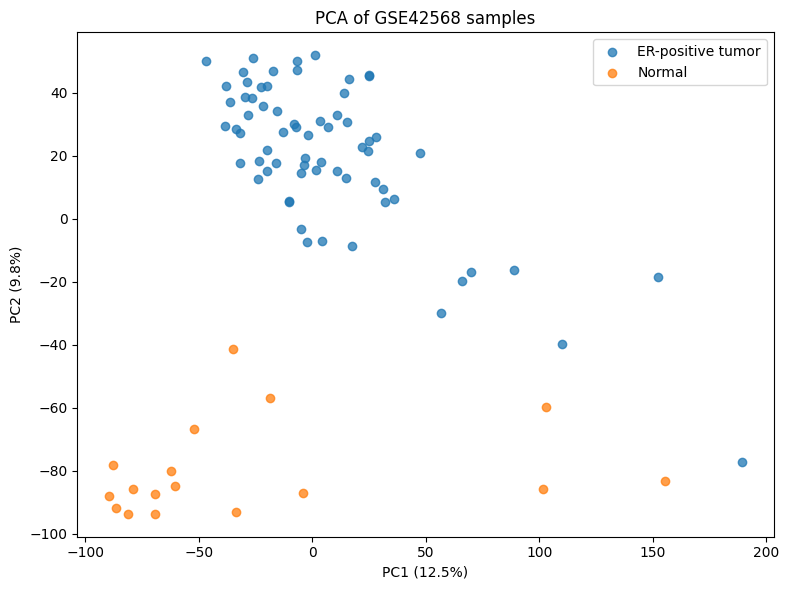

In [17]:
# 检查 B：看看两组样本整体分布是否有明显异常
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 每一行是样本，每一列是基因
X = gene_expr.loc[:, tumor_samples + normal_samples].T

# 去除零方差基因
variable_genes = X.columns[X.var(axis=0) > 0]
X = X[variable_genes]

# PCA 前对每个基因中心化并标准化
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

n_tumor = len(tumor_samples)

plt.figure(figsize=(8, 6))
plt.scatter(
    coords[:n_tumor, 0],
    coords[:n_tumor, 1],
    label="ER-positive tumor",
    alpha=0.75
)
plt.scatter(
    coords[n_tumor:, 0],
    coords[n_tumor:, 1],
    label="Normal",
    alpha=0.75
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of GSE42568 samples")
plt.legend()
plt.tight_layout()
plt.show()


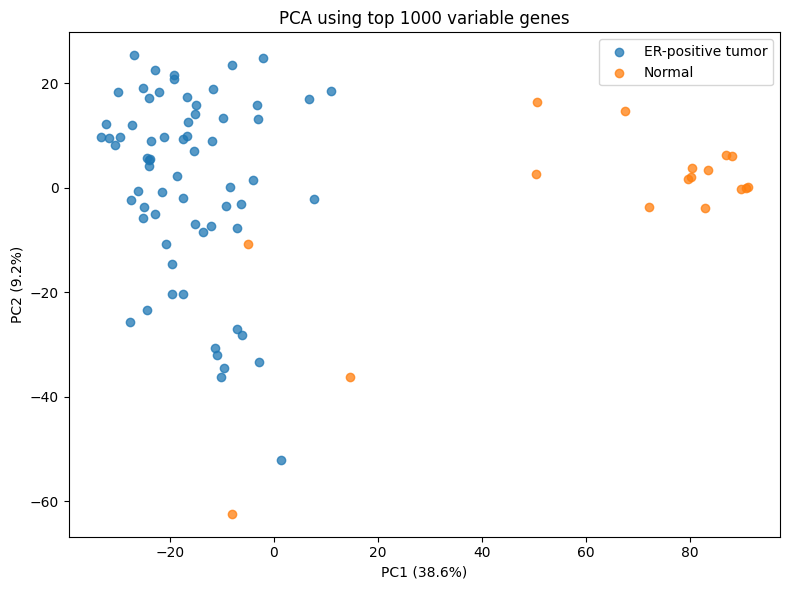

正常样本编号：
['GSM1045191', 'GSM1045192', 'GSM1045193', 'GSM1045194', 'GSM1045195', 'GSM1045196', 'GSM1045197', 'GSM1045198', 'GSM1045199', 'GSM1045200', 'GSM1045201', 'GSM1045202', 'GSM1045203', 'GSM1045204', 'GSM1045205', 'GSM1045206', 'GSM1045207']


In [18]:
# 重新检查 PCA 和正常样本分布

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 样本为行、基因为列
X = gene_expr.loc[:, tumor_samples + normal_samples].T

# 选择变异最大的1000个基因
gene_variance = X.var(axis=0)
top_genes = gene_variance.nlargest(1000).index
X_top = X[top_genes]

# 仅中心化，不做逐基因标准化
X_centered = X_top - X_top.mean(axis=0)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_centered)

n_tumor = len(tumor_samples)

plt.figure(figsize=(8, 6))
plt.scatter(
    coords[:n_tumor, 0],
    coords[:n_tumor, 1],
    label="ER-positive tumor",
    alpha=0.75
)
plt.scatter(
    coords[n_tumor:, 0],
    coords[n_tumor:, 1],
    label="Normal",
    alpha=0.75
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA using top 1000 variable genes")
plt.legend()
plt.tight_layout()
plt.show()

# 打印正常样本编号，便于后续核查
print("正常样本编号：")
print(normal_samples)


In [19]:

# 将 PCA 坐标与样本编号、分组对应起来
pca_df = pd.DataFrame({
    "sample_id": tumor_samples + normal_samples,
    "group": (
        ["ER_positive_tumor"] * len(tumor_samples)
        + ["Normal"] * len(normal_samples)
    ),
    "PC1": coords[:, 0],
    "PC2": coords[:, 1]
})

# 计算样本到所属组 PCA 中心的距离
pca_df["distance_to_group_center"] = np.nan

for group_name, indices in pca_df.groupby("group").groups.items():
    center = pca_df.loc[indices, ["PC1", "PC2"]].mean()
    distance = np.sqrt(
        ((pca_df.loc[indices, ["PC1", "PC2"]] - center) ** 2)
        .sum(axis=1)
    )
    pca_df.loc[indices, "distance_to_group_center"] = distance

# 分别查看两组距离中心最远的5个样本
for group_name in pca_df["group"].unique():
    print(f"\n{group_name}：距离组中心最远的5个样本")
    print(
        pca_df[pca_df["group"] == group_name]
        .sort_values("distance_to_group_center", ascending=False)
        .head(5)
        .to_string(index=False)
    )



ER_positive_tumor：距离组中心最远的5个样本
 sample_id             group        PC1        PC2  distance_to_group_center
GSM1045266 ER_positive_tumor   1.458319 -52.025793                 55.834497
GSM1045225 ER_positive_tumor -10.143565 -36.266493                 37.673733
GSM1045298 ER_positive_tumor  -2.903413 -33.422976                 36.856078
GSM1045296 ER_positive_tumor  -9.476228 -34.466771                 36.021208
GSM1045293 ER_positive_tumor -10.946709 -32.033309                 33.366210

Normal：距离组中心最远的5个样本
 sample_id  group       PC1        PC2  distance_to_group_center
GSM1045193 Normal -7.947441 -62.361234                 93.287844
GSM1045194 Normal -4.950227 -10.720273                 69.763440
GSM1045192 Normal 14.585801 -36.244102                 59.636660
GSM1045196 Normal 91.099781   0.150305                 26.910505
GSM1045204 Normal 90.719177  -0.118941                 26.497629


In [20]:

# 优先检查 PCA 中偏离较明显的样本
check_ids = [
    "GSM1045192",
    "GSM1045193",
    "GSM1045194",
    "GSM1045196",
    "GSM1045204",
    "GSM1045266",
    "GSM1045225",
    "GSM1045298",
    "GSM1045296",
    "GSM1045293"
]

# 1. 查看样本元数据
print("=== 样本元数据 ===")
print(
    meta[meta["sample_id"].isin(check_ids)]
    .to_string(index=False)
)

# 2. 查看这些样本的表达分布
print("\n=== 样本表达分布 ===")
sample_stats = pd.DataFrame({
    "mean": gene_expr[check_ids].mean(),
    "std": gene_expr[check_ids].std(),
    "min": gene_expr[check_ids].min(),
    "median": gene_expr[check_ids].median(),
    "max": gene_expr[check_ids].max(),
    "floor_fraction": (
        gene_expr[check_ids].sub(2.312811642).abs() < 1e-6
    ).mean()
})

print(sample_stats.round(4).to_string())


=== 样本元数据 ===
 sample_id                       title                source                                                                                                                                                                                                                characteristics
GSM1045192  Normal breast, N4_14_12_04 Breast tissue, normal    tissue: normal breast; age: NA; er_status: NA; size: NA; grade: NA; lymph node status: NA; relapse free survival time_days: NA; relapse free survival event: NA; overall survival time_days: NA; overall survival event: NA
GSM1045193  Normal breast, N5_15_12_04 Breast tissue, normal    tissue: normal breast; age: NA; er_status: NA; size: NA; grade: NA; lymph node status: NA; relapse free survival time_days: NA; relapse free survival event: NA; overall survival time_days: NA; overall survival event: NA
GSM1045194  Normal breast, N6_14_12_04 Breast tissue, normal    tissue: normal breast; age: NA; er_status: NA; size: NA; grade: NA; ly

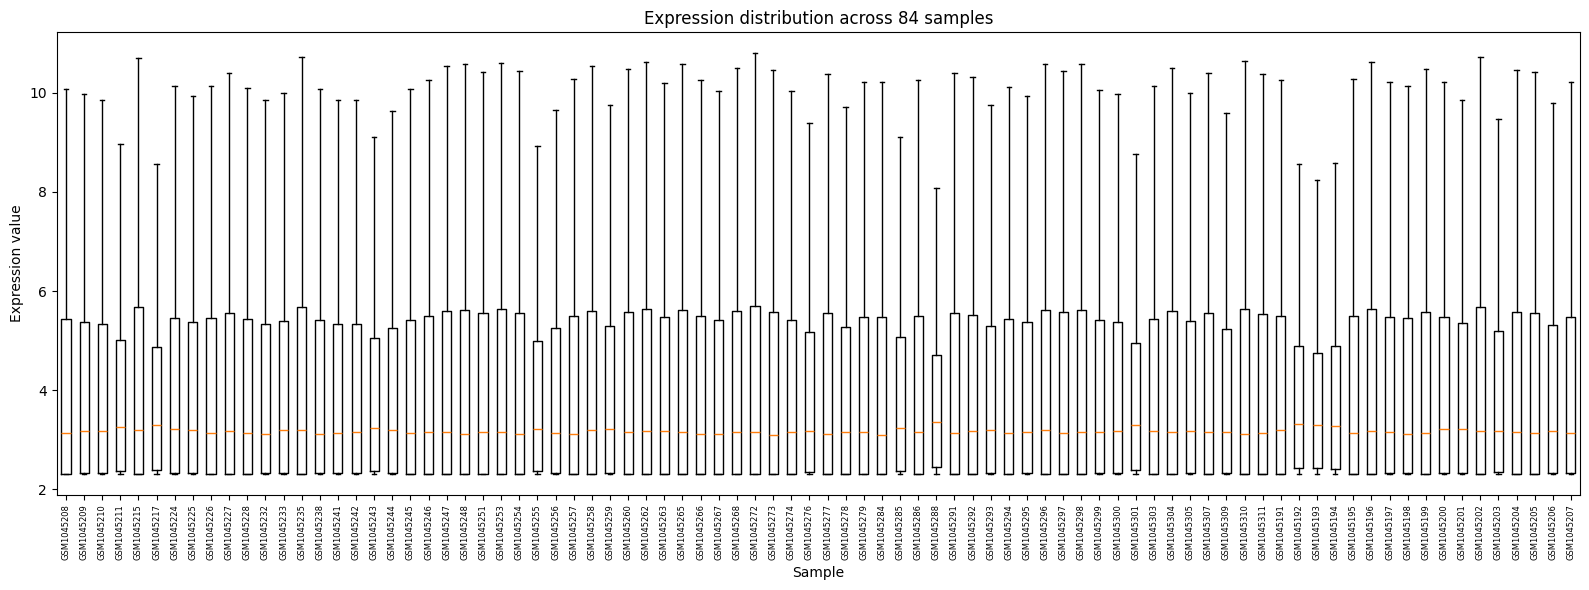

In [21]:

import matplotlib.pyplot as plt

# 只使用参与差异分析的样本
selected_samples = tumor_samples + normal_samples
plot_expr = gene_expr[selected_samples]

# 每个样本一个箱线图
plt.figure(figsize=(16, 6))

plt.boxplot(
    [plot_expr[s].values for s in selected_samples],
    showfliers=False
)

plt.xticks(
    range(1, len(selected_samples) + 1),
    selected_samples,
    rotation=90,
    fontsize=6
)

plt.ylabel("Expression value")
plt.xlabel("Sample")
plt.title("Expression distribution across 84 samples")
plt.tight_layout()
plt.show()


In [22]:

# 样本之间的 Pearson 相关系数
tumor_corr = tumor_expr.corr()
normal_corr = normal_expr.corr()

# 取相关矩阵上三角，避免重复计算和对角线
tumor_upper = tumor_corr.to_numpy()[
    np.triu_indices(len(tumor_samples), k=1)
]
normal_upper = normal_corr.to_numpy()[
    np.triu_indices(len(normal_samples), k=1)
]

print("肿瘤组样本间相关系数中位数：",
      np.median(tumor_upper))
print("正常组样本间相关系数中位数：",
      np.median(normal_upper))


肿瘤组样本间相关系数中位数： 0.9196494156690167
正常组样本间相关系数中位数： 0.9558276455734502


可以！我们先把目前完成的内容整理成一份简单的阶段性总结，方便你自己记录，也可以之后拿去和组员讨论。

# S1 第一版阶段性总结：GSE42568 差异表达分析

## 一、分析目的

以 ER 阳性乳腺癌为研究对象，利用乳腺癌组织与正常乳腺组织的基因表达数据，筛选疾病相关的差异表达基因，为后续基于药物表达逆转的药物重定位研究提供疾病基因签名。

## 二、数据与分组

- 数据集： GSE42568
- 芯片平台： GPL570，Affymetrix Human Genome U133 Plus 2.0 Array
- 样本总数： 121 个，其中 104 个乳腺癌样本、17 个正常乳腺组织样本。
- 本次分析分组：
  - ER 阳性乳腺癌组：67 个样本。
  - 正常乳腺组织组：17 个样本。
  - 暂不纳入分析：37 个样本，包括 ER 阴性肿瘤和 ER 状态缺失的肿瘤样本。

## 三、数据处理流程

1. 使用 Python 和 GEOparse 获取 GSE42568 数据及样本元信息。
2. 根据组织类型和 ER 状态筛选研究样本。
3. 将 121 个样本的表达数据合并为表达矩阵，得到 54,675 个探针。
4. 根据 GPL570 平台注释，将探针映射到基因符号。
5. 排除没有基因符号或包含多个基因符号的探针；对于同一基因对应的多个探针，采用表达值中位数进行汇总。
6. 最终得到包含 21,655 个基因、121 个样本的基因表达矩阵。
7. 提取 67 个 ER 阳性肿瘤样本和 17 个正常样本，采用 Welch 双样本 t 检验进行初步差异表达分析，并使用 Benjamini–Hochberg 方法校正多重检验。

## 四、第一版分析结果

参与检验的基因

# 21,655

FDR＜0.05 的基因

# 7,615

显著上调基因

# 4,539

显著下调基因

# 3,076

以上为当前 Welch 检验得到的探索性结果，尚不是最终确认的疾病基因签名。

部分初步结果显示，`COL10A1`、`CGN`、`FBXL16` 等基因在肿瘤组中表达较高；`SPG20`、`LDHB`、`FABP5` 等基因在肿瘤组中表达较低。上述基因目前仅作为初步候选，需要结合后续分析进一步确认。

## 五、数据质量初步检查

- 表达矩阵没有缺失值，探针 ID 和基因符号均已完成初步整理。
- 样本箱线图显示，各样本的整体表达分布较为相似。
- 肿瘤组样本间 Pearson 相关系数中位数约为 0.920，正常组约为 0.956。
- PCA 显示肿瘤组与正常组整体分离，但部分样本偏离各自组的主体分布。目前尚无充分证据认定这些样本存在严重质量问题，因此暂时保留全部样本。

## 六、目前存在的局限与下一步计划

1. 优化差异分析方法： 当前采用 Welch 检验，后续考虑使用更适合微阵列数据的 limma 重新计算。
2. 检查数据预处理和批次信息： 进一步核实表达数据的预处理方式及是否存在可用的批次信息。
3. 确定疾病基因签名： 根据差异表达统计结果，整理上调、下调基因集合，并保留完整的带方向基因排序表。
4. 开展药物逆转分析： 将疾病基因签名与药物扰动表达数据进行比较，筛选可能逆转疾病异常表达模式的候选药物。

当前阶段的结论： 已完成 GSE42568 的样本分组、表达矩阵构建、初步质量检查和第一版差异表达分析，形成了可供后续优化的候选基因结果。下一阶段的重点是提高差异表达结果的可靠性，并构建正式的疾病基因签名 S1。

In [23]:
import shutil

print("R 是否安装：", shutil.which("R"))
print("Rscript 是否安装：", shutil.which("Rscript"))

R 是否安装： None
Rscript 是否安装： None


In [24]:
print("gene_expr:", "gene_expr" in globals())
print("tumor_samples:", "tumor_samples" in globals())
print("normal_samples:", "normal_samples" in globals())

gene_expr: True
tumor_samples: True
normal_samples: True


In [25]:
print(gene_expr.shape)
print(len(tumor_samples))
print(len(normal_samples))
print(gene_expr.index[:5].tolist())
print(gene_expr.columns[:5].tolist())

(21655, 121)
67
17
['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1']
['GSM1045191', 'GSM1045192', 'GSM1045193', 'GSM1045194', 'GSM1045195']


## 先把 84 个分析样本的表达矩阵和分组信息导出为 CSV，再交给 R 的 limma 分析。

In [26]:
from pathlib import Path
import pandas as pd

# 1. 创建输出文件夹
output_dir = Path("gse42568_limma")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. 按照固定顺序选取 84 个样本
selected_samples = tumor_samples + normal_samples

expr_selected = gene_expr.loc[:, selected_samples].copy()

# 3. 检查样本数量与矩阵形状
assert len(tumor_samples) == 67
assert len(normal_samples) == 17
assert expr_selected.shape == (21655, 84)
assert expr_selected.columns.is_unique
assert expr_selected.index.is_unique
assert not expr_selected.isna().any().any()

# 4. 导出表达矩阵：行是基因，列是样本
expr_file = output_dir / "expression_matrix.csv"
expr_selected.to_csv(expr_file, index_label="gene_symbol")

# 5. 导出样本分组信息
group_df = pd.DataFrame({
    "sample_id": selected_samples,
    "group": (
        ["Tumor"] * len(tumor_samples)
        + ["Normal"] * len(normal_samples)
    )
})

group_file = output_dir / "sample_groups.csv"
group_df.to_csv(group_file, index=False)

# 6. 显示导出结果
print("表达矩阵文件：", expr_file.resolve())
print("分组文件：", group_file.resolve())
print("表达矩阵形状：", expr_selected.shape)
print("\n样本分组统计：")
print(group_df["group"].value_counts())

表达矩阵文件： E:\生物医学信息\gse42568_limma\expression_matrix.csv
分组文件： E:\生物医学信息\gse42568_limma\sample_groups.csv
表达矩阵形状： (21655, 84)

样本分组统计：
group
Tumor     67
Normal    17
Name: count, dtype: int64


In [27]:
from pathlib import Path
import pandas as pd

result_file = Path(
    r"E:\生物医学信息\gse42568_limma\limma_all_genes.csv"
)

limma_df = pd.read_csv(result_file)

print("结果表形状：", limma_df.shape)
print("\n列名：")
print(limma_df.columns.tolist())

print("\n最显著的 10 个上调基因：")
print(
    limma_df[limma_df["logFC"] > 0]
    .sort_values("adj.P.Val")
    [["gene_symbol", "logFC", "P.Value", "adj.P.Val"]]
    .head(10)
    .to_string(index=False)
)

print("\n最显著的 10 个下调基因：")
print(
    limma_df[limma_df["logFC"] < 0]
    .sort_values("adj.P.Val")
    [["gene_symbol", "logFC", "P.Value", "adj.P.Val"]]
    .head(10)
    .to_string(index=False)
)

结果表形状： (21655, 7)

列名：
['gene_symbol', 'logFC', 'AveExpr', 't', 'P.Value', 'adj.P.Val', 'B']

最显著的 10 个上调基因：
gene_symbol    logFC      P.Value    adj.P.Val
      PRKCZ 2.675350 1.598859e-26 1.282344e-23
     SPINT2 4.199991 5.373860e-23 1.482091e-20
        DSP 5.024820 7.996024e-23 2.111633e-20
      ESRP1 3.917954 1.867539e-22 4.648454e-20
       SOX4 3.193700 2.476416e-22 5.958532e-20
   PAFAH1B3 3.996965 1.071071e-21 2.108549e-19
       SDC1 4.292510 2.806171e-21 4.810309e-19
     FAM83H 1.979212 3.601462e-21 5.999204e-19
      UHRF1 3.664394 1.075533e-20 1.687729e-18
      HOOK1 3.017306 1.504518e-20 2.327166e-18

最显著的 10 个下调基因：
gene_symbol     logFC      P.Value    adj.P.Val
     IGSF10 -2.629211 4.751297e-33 1.028893e-28
        MME -4.591920 9.584740e-31 1.037788e-26
  LOC284825 -4.164352 3.231970e-30 2.332943e-26
     ACVR1C -5.290740 6.532450e-29 3.536505e-25
   TMEM132C -3.797254 9.958698e-29 4.035567e-25
   PGM5-AS1 -3.587571 1.195685e-28 4.035567e-25
    ALDH1L1 -1.777623 

In [28]:
import numpy as np
import pandas as pd

# 需要核实的代表性基因
check_genes = [
    "PRKCZ", "SPINT2", "DSP", "ESRP1", "SOX4",
    "UHRF1", "IGSF10", "MME", "ACVR1C", "ALDH1L1"
]

rows = []

for gene in check_genes:
    if gene not in gene_expr.index:
        print(f"未在表达矩阵中找到：{gene}")
        continue

    tumor_values = gene_expr.loc[gene, tumor_samples].astype(float)
    normal_values = gene_expr.loc[gene, normal_samples].astype(float)

    result_row = limma_df.loc[
        limma_df["gene_symbol"] == gene
    ].iloc[0]

    rows.append({
        "gene": gene,
        "Tumor_mean": tumor_values.mean(),
        "Normal_mean": normal_values.mean(),
        "Mean_difference": tumor_values.mean() - normal_values.mean(),
        "limma_logFC": result_row["logFC"],
        "adj.P.Val": result_row["adj.P.Val"],
        "Tumor_median": tumor_values.median(),
        "Normal_median": normal_values.median()
    })

check_df = pd.DataFrame(rows)
print(check_df.round(4).to_string(index=False))

   gene  Tumor_mean  Normal_mean  Mean_difference  limma_logFC  adj.P.Val  Tumor_median  Normal_median
  PRKCZ      6.6612       3.9859           2.6753       2.6753        0.0        6.5964         3.4986
 SPINT2     10.9828       6.7829           4.2000       4.2000        0.0       10.9791         6.5372
    DSP     10.5223       5.4975           5.0248       5.0248        0.0       10.6145         5.2569
  ESRP1      7.6259       3.7080           3.9180       3.9180        0.0        7.6475         3.1656
   SOX4      8.5054       5.3117           3.1937       3.1937        0.0        8.6703         5.0601
  UHRF1      7.4732       3.8088           3.6644       3.6644        0.0        7.3956         2.9924
 IGSF10      2.5489       5.1781          -2.6292      -2.6292        0.0        2.3997         5.4689
    MME      3.7519       8.3438          -4.5919      -4.5919        0.0        3.4637         9.1843
 ACVR1C      3.2443       8.5350          -5.2907      -5.2907        0.0

In [29]:
# adj.P.Val为什么都是0
pd.set_option("display.float_format", "{:.3e}".format)

print(
    limma_df.loc[
        limma_df["gene_symbol"].isin([
            "PRKCZ", "SPINT2", "DSP", "ESRP1",
            "SOX4", "UHRF1", "IGSF10", "MME",
            "ACVR1C", "ALDH1L1"
        ]),
        ["gene_symbol", "logFC", "P.Value", "adj.P.Val"]
    ].sort_values("adj.P.Val").to_string(index=False)
)

gene_symbol      logFC   P.Value  adj.P.Val
     IGSF10 -2.629e+00 4.751e-33  1.029e-28
        MME -4.592e+00 9.585e-31  1.038e-26
     ACVR1C -5.291e+00 6.532e-29  3.537e-25
    ALDH1L1 -1.778e+00 1.305e-28  4.036e-25
      PRKCZ  2.675e+00 1.599e-26  1.282e-23
     SPINT2  4.200e+00 5.374e-23  1.482e-20
        DSP  5.025e+00 7.996e-23  2.112e-20
      ESRP1  3.918e+00 1.868e-22  4.648e-20
       SOX4  3.194e+00 2.476e-22  5.959e-20
      UHRF1  3.664e+00 1.076e-20  1.688e-18


In [30]:
pd.reset_option("display.float_format")

## 正式构建疾病表达签名

In [31]:

from pathlib import Path
import pandas as pd

output_dir = Path(r"E:\生物医学信息\gse42568_limma")

# 读取完整的 limma 结果
limma_df = pd.read_csv(output_dir / "limma_all_genes.csv")

# 筛选 FDR < 0.05 的显著差异基因
sig_df = limma_df[
    (limma_df["adj.P.Val"] < 0.05)
    & limma_df["adj.P.Val"].notna()
].copy()

# 按肿瘤相对于正常组织的表达变化方向划分
up_df = sig_df[sig_df["logFC"] > 0].copy()
down_df = sig_df[sig_df["logFC"] < 0].copy()

# 按校正后 P 值排序
up_df = up_df.sort_values("adj.P.Val")
down_df = down_df.sort_values("adj.P.Val")

# 保存结果
up_df.to_csv(
    output_dir / "disease_up_genes.csv",
    index=False
)
down_df.to_csv(
    output_dir / "disease_down_genes.csv",
    index=False
)

print("上调基因数：", len(up_df))
print("下调基因数：", len(down_df))
print("总显著差异基因数：", len(sig_df))

print("\n上调基因前 5 名：")
print(up_df[["gene_symbol", "logFC", "adj.P.Val"]].head().to_string(index=False))

print("\n下调基因前 5 名：")
print(down_df[["gene_symbol", "logFC", "adj.P.Val"]].head().to_string(index=False))

print("\n文件保存目录：", output_dir)


上调基因数： 3422
下调基因数： 3644
总显著差异基因数： 7066

上调基因前 5 名：
gene_symbol    logFC    adj.P.Val
      PRKCZ 2.675350 1.282344e-23
     SPINT2 4.199991 1.482091e-20
        DSP 5.024820 2.111633e-20
      ESRP1 3.917954 4.648454e-20
       SOX4 3.193700 5.958532e-20

下调基因前 5 名：
gene_symbol     logFC    adj.P.Val
     IGSF10 -2.629211 1.028893e-28
        MME -4.591920 1.037788e-26
  LOC284825 -4.164352 2.332943e-26
     ACVR1C -5.290740 3.536505e-25
   TMEM132C -3.797254 4.035567e-25

文件保存目录： E:\生物医学信息\gse42568_limma


In [32]:
print("最显著的 10 个上调基因：")
print(
    limma_df[limma_df["logFC"] > 0]
    .sort_values("adj.P.Val")
    [["gene_symbol", "logFC", "P.Value", "adj.P.Val"]]
    .head(10)
    .to_string(index=False)
)

print("\n最显著的 10 个下调基因：")
print(
    limma_df[limma_df["logFC"] < 0]
    .sort_values("adj.P.Val")
    [["gene_symbol", "logFC", "P.Value", "adj.P.Val"]]
    .head(10)
    .to_string(index=False)
)

最显著的 10 个上调基因：
gene_symbol    logFC      P.Value    adj.P.Val
      PRKCZ 2.675350 1.598859e-26 1.282344e-23
     SPINT2 4.199991 5.373860e-23 1.482091e-20
        DSP 5.024820 7.996024e-23 2.111633e-20
      ESRP1 3.917954 1.867539e-22 4.648454e-20
       SOX4 3.193700 2.476416e-22 5.958532e-20
   PAFAH1B3 3.996965 1.071071e-21 2.108549e-19
       SDC1 4.292510 2.806171e-21 4.810309e-19
     FAM83H 1.979212 3.601462e-21 5.999204e-19
      UHRF1 3.664394 1.075533e-20 1.687729e-18
      HOOK1 3.017306 1.504518e-20 2.327166e-18

最显著的 10 个下调基因：
gene_symbol     logFC      P.Value    adj.P.Val
     IGSF10 -2.629211 4.751297e-33 1.028893e-28
        MME -4.591920 9.584740e-31 1.037788e-26
  LOC284825 -4.164352 3.231970e-30 2.332943e-26
     ACVR1C -5.290740 6.532450e-29 3.536505e-25
   TMEM132C -3.797254 9.958698e-29 4.035567e-25
   PGM5-AS1 -3.587571 1.195685e-28 4.035567e-25
    ALDH1L1 -1.777623 1.304501e-28 4.035567e-25
      AQPEP -4.140660 3.675490e-28 9.256855e-25
       GPD1 -3.08649